# From longitude and latitude to a projected plane

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/15-projections.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/15-projections.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `10fd23b8e6a0414a432e81468fed1f584ca23e5c567b7546823fa476fd425b68`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# From longitude and latitude to a projected plane

**Lesson 15 · Original synthetic data · Independent educational project**

## Objectives

Calculate a spherical Mercator projection; diagnose polar distortion.

[Previous](14-maps.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/15-projections.ipynb) · [Next](16-terrain.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=15-projections.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

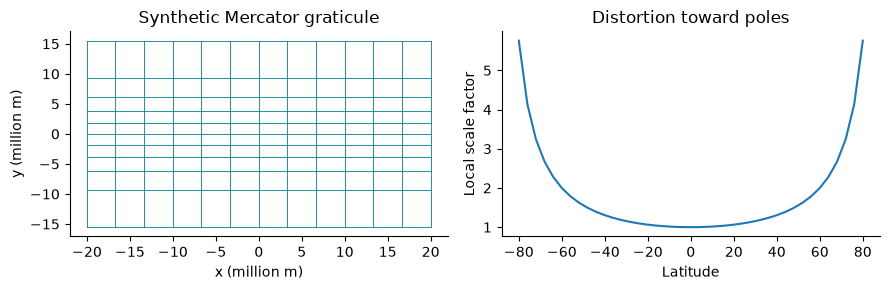

In [2]:
radius = lab.EARTH_RADIUS_M
lat = np.linspace(-80, 80, 41); lon = np.linspace(-180, 180, 73)
x = radius*np.deg2rad(lon)
y = radius*np.log(np.tan(np.pi/4+np.deg2rad(lat)/2))
recovered = np.rad2deg(2*np.arctan(np.exp(y/radius))-np.pi/2)
assert np.allclose(lat, recovered)
scale = 1/np.cos(np.deg2rad(lat))
assert scale.max() > 5
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for latitude_y in y[::4]: axes[0].plot(x/1e6, np.full_like(x, latitude_y)/1e6, color="teal", lw=.6)
for longitude_x in x[::6]: axes[0].plot(np.full_like(y, longitude_x)/1e6, y/1e6, color="teal", lw=.6)
axes[0].set(xlabel="x (million m)", ylabel="y (million m)", title="Synthetic Mercator graticule")
axes[1].plot(lat, scale)
axes[1].set(xlabel="Latitude", ylabel="Local scale factor", title="Distortion toward poles")
plt.tight_layout(); plt.show()

## Exercise

Evaluate the scale factor at 0°, 45° and 75°. Explain why this projection is unsuitable for visual area comparisons.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

The spherical equations are a teaching approximation. Coordinate reference systems, ellipsoids and authoritative transformations matter for real spatial analysis.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://proj.org/en/stable/operations/projections/merc.html) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).